In [4]:
import os, shutil, tensorflow as tf, numpy as np, json
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetV2S
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import zipfile

RICE_INPUT = "/kaggle/input/datasets/afzaalsattar/rice-disease-dataset"
RICE_CLEAN = "/kaggle/working/rice_clean"

# Copy each split separately
os.makedirs(RICE_CLEAN, exist_ok=True)
for split in ["train", "valid", "test"]:
    src = os.path.join(RICE_INPUT, split)
    dst = os.path.join(RICE_CLEAN, split)
    if os.path.exists(dst):
        print(f"{split}/ already exists, skipping.")
        continue
    if not os.path.exists(src):
        print(f"❌ {split}/ not found at {src}")
        continue
    print(f"Copying {split}/...")
    shutil.copytree(src, dst)
    print(f"  Done.")

# Validate each split
def validate(root):
    removed = 0
    for cls in os.listdir(root):
        cls_dir = os.path.join(root, cls)
        if not os.path.isdir(cls_dir): continue
        for f in os.listdir(cls_dir):
            fpath = os.path.join(cls_dir, f)
            try:
                tf.image.decode_image(tf.io.read_file(fpath))
            except:
                os.remove(fpath)
                removed += 1
    return removed

print("\n=== Validating ===")
for split in ["train", "valid", "test"]:
    r = validate(os.path.join(RICE_CLEAN, split))
    print(f"  {split}/: removed {r} corrupt files")

print("\n=== Class counts ===")
for split in ["train", "valid", "test"]:
    print(f"\n{split}/")
    split_dir = os.path.join(RICE_CLEAN, split)
    total = 0
    for cls in sorted(os.listdir(split_dir)):
        cls_dir = os.path.join(split_dir, cls)
        if not os.path.isdir(cls_dir): continue
        n = len([f for f in os.listdir(cls_dir) if f.lower().endswith((".jpg",".jpeg",".png"))])
        print(f"  {cls}: {n}")
        total += n
    print(f"  TOTAL: {total}")

print("\n✅ Dataset ready!")

train/ already exists, skipping.
valid/ already exists, skipping.
test/ already exists, skipping.

=== Validating ===
  train/: removed 0 corrupt files
  valid/: removed 0 corrupt files
  test/: removed 0 corrupt files

=== Class counts ===

train/
  Bacterial Leaf Blight: 1335
  Brown Spot: 1317
  Healthy Rice Leaf: 1362
  Leaf Blast: 1317
  Leaf scald: 1284
  Sheath Blight: 1350
  TOTAL: 7965

valid/
  Bacterial Leaf Blight: 144
  Brown Spot: 133
  Healthy Rice Leaf: 130
  Leaf Blast: 113
  Leaf scald: 127
  Sheath Blight: 116
  TOTAL: 763

test/
  Bacterial Leaf Blight: 47
  Brown Spot: 65
  Healthy Rice Leaf: 66
  Leaf Blast: 67
  Leaf scald: 73
  Sheath Blight: 62
  TOTAL: 380

✅ Dataset ready!


In [5]:
IMG_SIZE = (384, 384)
BATCH_SIZE = 16          # safe for V2S at 384px
SEED = 42

TRAIN_DIR = os.path.join(RICE_CLEAN, "train")
VAL_DIR   = os.path.join(RICE_CLEAN, "valid")

# Load directly from existing splits — no random resplit needed
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", seed=SEED
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", seed=SEED
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Classes:", class_names)
print("Number of classes:", NUM_CLASSES)

with open("/kaggle/working/rice_class_names_raw.json", "w") as f:
    json.dump(class_names, f, indent=2)

# Class weights from train folder only
labels_flat = []
for i, cls in enumerate(class_names):
    cls_dir = os.path.join(TRAIN_DIR, cls)
    n = len([f for f in os.listdir(cls_dir) if f.lower().endswith((".jpg",".jpeg",".png"))])
    labels_flat.extend([i] * n)
labels_flat = np.array(labels_flat)
cw = compute_class_weight("balanced", classes=np.unique(labels_flat), y=labels_flat)
class_weight_dict = {i: w for i, w in enumerate(cw)}
print("\nClass weights:")
for i, cls in enumerate(class_names):
    print(f"  {cls}: {class_weight_dict[i]:.3f}")

# No augmentation — dataset is pre-augmented
def prep_train(img, lbl): return preprocess_input(img), lbl
def prep_val(img, lbl):   return preprocess_input(img), lbl

train_ds_p = train_ds.map(prep_train, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
val_ds_p   = val_ds.map(prep_val,     num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

print("\n✅ Data ready!")

Found 7965 files belonging to 6 classes.
Found 763 files belonging to 6 classes.
Classes: ['Bacterial Leaf Blight', 'Brown Spot', 'Healthy Rice Leaf', 'Leaf Blast', 'Leaf scald', 'Sheath Blight']
Number of classes: 6

Class weights:
  Bacterial Leaf Blight: 0.994
  Brown Spot: 1.008
  Healthy Rice Leaf: 0.975
  Leaf Blast: 1.008
  Leaf scald: 1.034
  Sheath Blight: 0.983

✅ Data ready!


In [6]:
# Build model
base = EfficientNetV2S(include_top=False, weights="imagenet", input_shape=(384,384,3))
base.trainable = False

inputs  = keras.Input(shape=(384,384,3))
x = base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint("/kaggle/working/rice_best.keras", monitor="val_accuracy", save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7),
    keras.callbacks.BackupAndRestore("/kaggle/working/rice_backup/")
]

82420632/82420632 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [7]:
# Phase 1
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="categorical_crossentropy", metrics=["accuracy"])
print("\n=== PHASE 1: Frozen base (lr=1e-3) ===")
h1 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=5,
               class_weight=class_weight_dict, callbacks=callbacks)


=== PHASE 1: Frozen base (lr=1e-3) ===
Epoch 1/5


I0000 00:00:1782383055.016731     132 service.cc:152] XLA service 0x7eeca40a51c0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1782383055.016774     132 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1782383055.016778     132 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1782383059.729397     132 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-06-25 10:24:29.489647: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 10:24:29.638477: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 10:24:30.570893: E external/local_xl

497/498 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - accuracy: 0.4678 - loss: 1.5573

2026-06-25 10:25:59.662972: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 10:25:59.808849: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 10:26:00.716529: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 10:26:00.866261: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 10:26:02.344645: E external/local_xla/xla/stream_

498/498 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step - accuracy: 0.4680 - loss: 1.5567

2026-06-25 10:26:43.935984: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 10:26:44.077967: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 10:26:44.972578: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 10:26:45.119174: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 10:26:46.583985: E external/local_xla/xla/stream_

498/498 ━━━━━━━━━━━━━━━━━━━━ 182s 254ms/step - accuracy: 0.5721 - loss: 1.2430 - val_accuracy: 0.7431 - val_loss: 0.6779 - learning_rate: 0.0010
Epoch 2/5
498/498 ━━━━━━━━━━━━━━━━━━━━ 67s 134ms/step - accuracy: 0.6841 - loss: 0.8906 - val_accuracy: 0.7772 - val_loss: 0.5989 - learning_rate: 0.0010
Epoch 3/5
498/498 ━━━━━━━━━━━━━━━━━━━━ 67s 134ms/step - accuracy: 0.7066 - loss: 0.8316 - val_accuracy: 0.7890 - val_loss: 0.5298 - learning_rate: 0.0010
Epoch 4/5
498/498 ━━━━━━━━━━━━━━━━━━━━ 67s 133ms/step - accuracy: 0.7170 - loss: 0.7915 - val_accuracy: 0.7955 - val_loss: 0.5756 - learning_rate: 0.0010
Epoch 5/5
498/498 ━━━━━━━━━━━━━━━━━━━━ 67s 134ms/step - accuracy: 0.7253 - loss: 0.7731 - val_accuracy: 0.8087 - val_loss: 0.5427 - learning_rate: 0.0010


In [8]:
# Phase 2
base.trainable = True
model.compile(optimizer=keras.optimizers.Adam(1e-4),
              loss="categorical_crossentropy", metrics=["accuracy"])
print("\n=== PHASE 2: Full fine-tune (lr=1e-4) ===")
h2 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=10,
               class_weight=class_weight_dict, callbacks=callbacks)


=== PHASE 2: Full fine-tune (lr=1e-4) ===
Epoch 1/10


2026-06-25 10:33:09.082688: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 10:33:09.239788: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 10:33:12.242026: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 10:33:12.410888: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 10:33:13.600085: E external/local_xla/xla/stream_

497/498 ━━━━━━━━━━━━━━━━━━━━ 0s 415ms/step - accuracy: 0.6974 - loss: 0.9660

2026-06-25 10:37:55.632582: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 10:37:55.793189: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 10:37:58.902408: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 10:37:59.071143: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 10:38:00.358197: E external/local_xla/xla/stream_

498/498 ━━━━━━━━━━━━━━━━━━━━ 478s 643ms/step - accuracy: 0.7886 - loss: 0.6624 - val_accuracy: 0.9214 - val_loss: 0.2223 - learning_rate: 1.0000e-04
Epoch 2/10
498/498 ━━━━━━━━━━━━━━━━━━━━ 218s 437ms/step - accuracy: 0.9379 - loss: 0.1901 - val_accuracy: 0.9528 - val_loss: 0.1799 - learning_rate: 1.0000e-04
Epoch 3/10
498/498 ━━━━━━━━━━━━━━━━━━━━ 218s 437ms/step - accuracy: 0.9661 - loss: 0.0999 - val_accuracy: 0.9541 - val_loss: 0.2126 - learning_rate: 1.0000e-04
Epoch 4/10
498/498 ━━━━━━━━━━━━━━━━━━━━ 218s 438ms/step - accuracy: 0.9753 - loss: 0.0748 - val_accuracy: 0.9620 - val_loss: 0.1946 - learning_rate: 1.0000e-04
Epoch 5/10
498/498 ━━━━━━━━━━━━━━━━━━━━ 217s 436ms/step - accuracy: 0.9871 - loss: 0.0404 - val_accuracy: 0.9699 - val_loss: 0.1507 - learning_rate: 3.0000e-05
Epoch 6/10
498/498 ━━━━━━━━━━━━━━━━━━━━ 217s 436ms/step - accuracy: 0.9903 - loss: 0.0289 - val_accuracy: 0.9738 - val_loss: 0.1293 - learning_rate: 3.0000e-05
Epoch 7/10
498/498 ━━━━━━━━━━━━━━━━━━━━ 215s 431ms/

In [9]:
# Phase 3
model.compile(optimizer=keras.optimizers.Adam(3e-5),
              loss="categorical_crossentropy", metrics=["accuracy"])
print("\n=== PHASE 3: Extended fine-tune (lr=3e-5) ===")
h3 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=15,
               class_weight=class_weight_dict, callbacks=callbacks)


=== PHASE 3: Extended fine-tune (lr=3e-5) ===
Epoch 1/15
498/498 ━━━━━━━━━━━━━━━━━━━━ 463s 625ms/step - accuracy: 0.9936 - loss: 0.0172 - val_accuracy: 0.9790 - val_loss: 0.1247 - learning_rate: 3.0000e-05
Epoch 2/15
498/498 ━━━━━━━━━━━━━━━━━━━━ 217s 436ms/step - accuracy: 0.9950 - loss: 0.0147 - val_accuracy: 0.9777 - val_loss: 0.1625 - learning_rate: 3.0000e-05
Epoch 3/15
498/498 ━━━━━━━━━━━━━━━━━━━━ 217s 435ms/step - accuracy: 0.9956 - loss: 0.0142 - val_accuracy: 0.9764 - val_loss: 0.1618 - learning_rate: 3.0000e-05
Epoch 4/15
498/498 ━━━━━━━━━━━━━━━━━━━━ 217s 435ms/step - accuracy: 0.9954 - loss: 0.0153 - val_accuracy: 0.9790 - val_loss: 0.1445 - learning_rate: 9.0000e-06


In [10]:
# Save model
model.save("/kaggle/working/rice_final.keras")
print(f"\nModel saved. Size: {os.path.getsize('/kaggle/working/rice_final.keras')/1024/1024:.1f} MB")


Model saved. Size: 233.7 MB



=== Classification Report ===
                       precision    recall  f1-score   support

Bacterial Leaf Blight     0.9722    0.9722    0.9722       144
           Brown Spot     0.9632    0.9850    0.9740       133
    Healthy Rice Leaf     1.0000    1.0000    1.0000       130
           Leaf Blast     0.9727    0.9469    0.9596       113
           Leaf scald     0.9766    0.9843    0.9804       127
        Sheath Blight     0.9913    0.9828    0.9870       116

             accuracy                         0.9790       763
            macro avg     0.9793    0.9785    0.9789       763
         weighted avg     0.9791    0.9790    0.9790       763



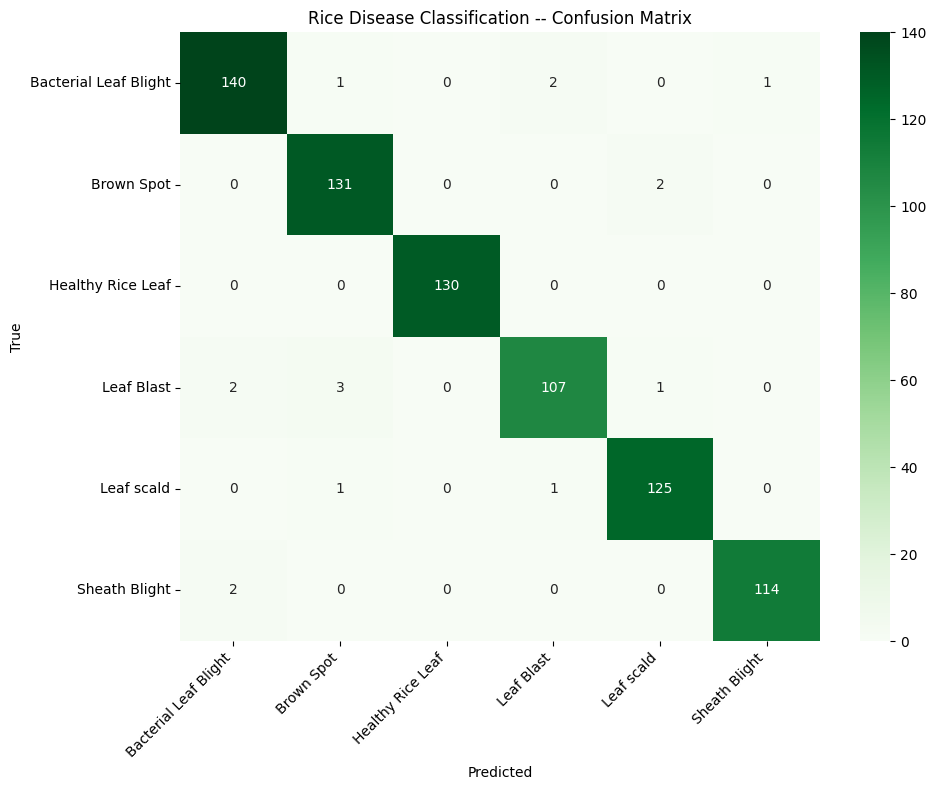


Final val accuracy: 97.90%


In [11]:
# Evaluation
y_true, y_pred = [], []
for imgs, lbls in val_ds_p:
    preds = model.predict(imgs, verbose=0)
    y_true.extend(np.argmax(lbls.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))
 
print("\n=== Classification Report ===")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
 
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title("Rice Disease Classification -- Confusion Matrix")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
plt.savefig("/kaggle/working/rice_confusion_matrix.png", dpi=150)
plt.show()
print(f"\nFinal val accuracy: {max(h3.history['val_accuracy'])*100:.2f}%")

In [12]:
# RICE -- CELL D: Generate class_map + package zip
# ============================================================
rice_class_map = {}
production_class_names = []
for cls in class_names:
    key = "rice__" + cls.lower().replace(" ", "_").replace("-", "_")
    production_class_names.append(key)
    rice_class_map[key] = {"crop": "Rice", "disease": cls}
 
with open("/kaggle/working/rice_class_map.json", "w") as f:
    json.dump(rice_class_map, f, indent=2)
with open("/kaggle/working/rice_class_names.json", "w") as f:
    json.dump(production_class_names, f, indent=2)
 
print("=== rice_class_map.json ===")
print(json.dumps(rice_class_map, indent=2))
 
files = [
    "/kaggle/working/rice_final.keras",
    "/kaggle/working/rice_best.keras",
    "/kaggle/working/rice_class_map.json",
    "/kaggle/working/rice_class_names.json",
    "/kaggle/working/rice_confusion_matrix.png",
]
 
print("\n=== Output files ===")
for f in files:
    if os.path.exists(f):
        print(f"  OK  {f}  ({os.path.getsize(f)/1024/1024:.1f} MB)")
    else:
        print(f"  MISSING  {f}")
 
zip_path = "/kaggle/working/rice_model_package.zip"
with zipfile.ZipFile(zip_path, "w") as zf:
    for f in files:
        if os.path.exists(f):
            zf.write(f, arcname=os.path.basename(f))
print(f"\nZip: {zip_path} ({os.path.getsize(zip_path)/1024/1024:.1f} MB)")
print("\nDo Save Version -> Save & Run All (Commit) now!")
 

=== rice_class_map.json ===
{
  "rice__bacterial_leaf_blight": {
    "crop": "Rice",
    "disease": "Bacterial Leaf Blight"
  },
  "rice__brown_spot": {
    "crop": "Rice",
    "disease": "Brown Spot"
  },
  "rice__healthy_rice_leaf": {
    "crop": "Rice",
    "disease": "Healthy Rice Leaf"
  },
  "rice__leaf_blast": {
    "crop": "Rice",
    "disease": "Leaf Blast"
  },
  "rice__leaf_scald": {
    "crop": "Rice",
    "disease": "Leaf scald"
  },
  "rice__sheath_blight": {
    "crop": "Rice",
    "disease": "Sheath Blight"
  }
}

=== Output files ===
  OK  /kaggle/working/rice_final.keras  (233.7 MB)
  OK  /kaggle/working/rice_best.keras  (233.7 MB)
  OK  /kaggle/working/rice_class_map.json  (0.0 MB)
  OK  /kaggle/working/rice_class_names.json  (0.0 MB)
  OK  /kaggle/working/rice_confusion_matrix.png  (0.1 MB)

Zip: /kaggle/working/rice_model_package.zip (467.4 MB)

Do Save Version -> Save & Run All (Commit) now!
